<a href="https://colab.research.google.com/github/FazelPriyono/Pembelajaran-Mesin-2026/blob/main/TG11_244107020033_FazelPriyono.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS 11 - KLASIFIKASI 2

# PRAKTIKUM 1
## Langkah 1 - Import Library

In [ ]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

## Langkah 2 - Membuat Data Dummy

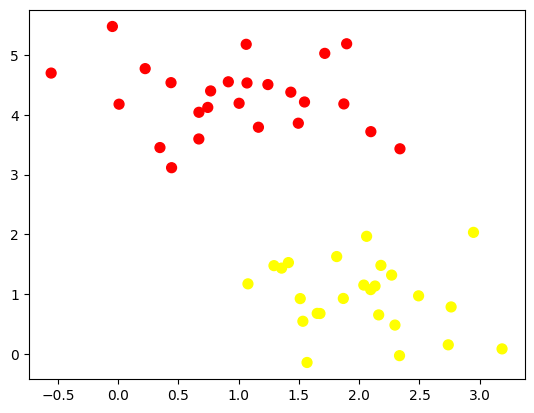

In [ ]:
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=50, centers=2,
                  random_state=0, cluster_std=0.60)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

## Langkah 3 - Buat Ilustrasi Garis Pemisah

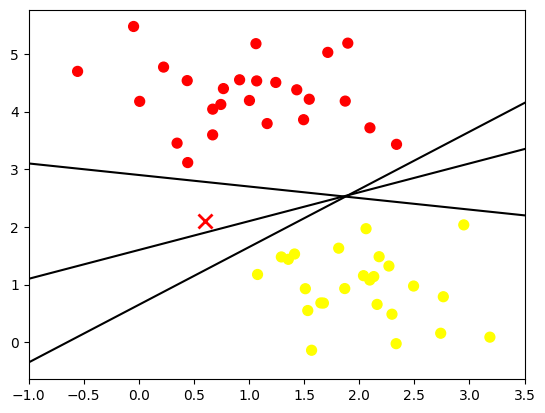

In [ ]:
# Rentang sumbu x untuk menggambar garis
xfit = np.linspace(-1, 3.5)

# Plot data dari Langkah 2
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# Titik data baru 'x'
plt.plot([0.6], [2.1], 'x', color='red', markeredgewidth=2, markersize=10)

# Tiga garis pemisah yang berbeda, dengan format (gradien m, intersep b)
for m, b in [(1, 0.65), (0.5, 1.6), (-0.2, 2.9)]:
    plt.plot(xfit, m * xfit + b, '-k')

# Batas sumbu x
plt.xlim(-1, 3.5)
plt.show()

## Langkah 4 - Ilustrasi Margin

(-1.0, 3.5)

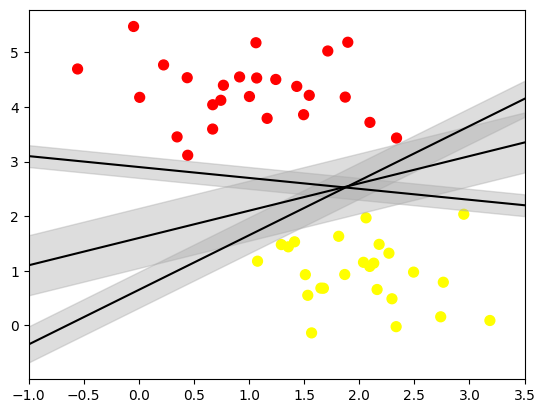

In [ ]:
xfit = np.linspace(-1, 3.5)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
                     color='#AAAAAA', alpha=0.4)

plt.xlim(-1, 3.5)

## Langkah 5 - Fitting Model

In [ ]:
from sklearn.svm import SVC # "Support vector classifier"
model = SVC(kernel='linear', C=1E10)
model.fit(X, y)

SVC(C=10000000000.0, kernel='linear')

fungsi untuk membantu visualisasi hasil fit model

In [ ]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

plotting dengan fungsi yang telah dibuat

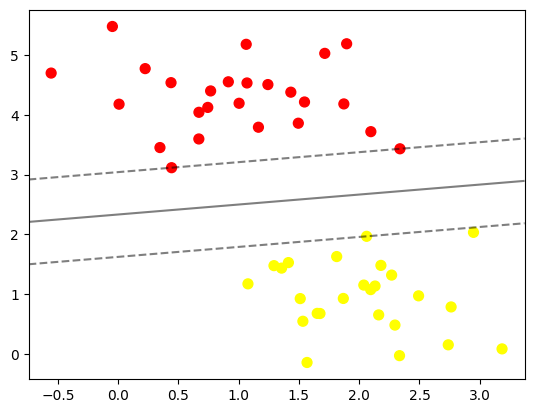

In [ ]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model)

menampilkan support vectors

In [ ]:
model.support_vectors_

array([[0.44359863, 3.11530945],
       [2.33812285, 3.43116792],
       [2.06156753, 1.96918596]])

## Langkah 6 - Membandingkan Model dengan Jumlah Data Berbeda

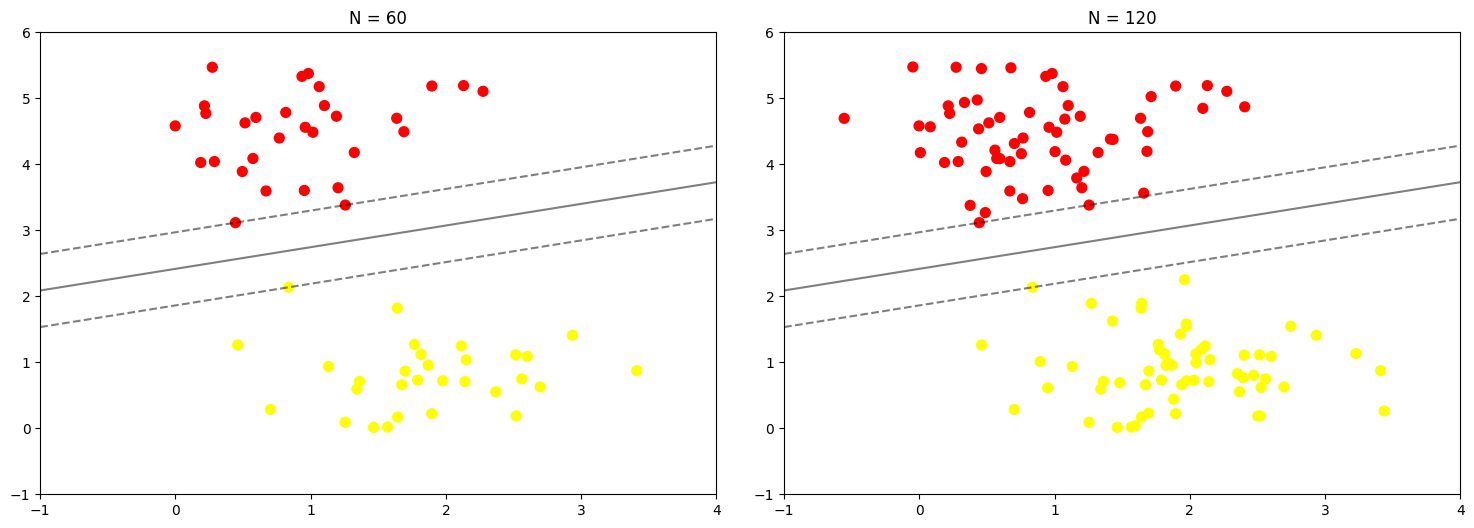

In [ ]:
def plot_svm(N=10, ax=None):
    X, y = make_blobs(n_samples=200, centers=2,
                      random_state=0, cluster_std=0.60)
    X = X[:N]
    y = y[:N]
    model = SVC(kernel='linear', C=1E10)
    model.fit(X, y)

    ax = ax or plt.gca()
    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(model, ax)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))


## Langkah 7 - Interaksi Jumlah Data Menggunakan ipywidgets

In [ ]:
!pip install ipywidgets

In [ ]:
# jumlah data dapat dipilih di antara 10 atau 200 buah data, telihat tidak ada perubahan pada model

from ipywidgets import interact, fixed
interact(plot_svm, N=[10, 200], ax=fixed(None))

interactive(children=(Dropdown(description='N', options=(10, 200), value=10), Output()), _dom_classes=('widget…

<function __main__.plot_svm(N=10, ax=None)>

# PRAKTIKUM 2
## Langkah 1 - Ilustrasi Data Non-Linier

## 1a - Import Library

In [1]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

## 1b - Buat Kembali Fungsi Plotting

In [2]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

## 1c - Data dummy melingkar (make_circles)

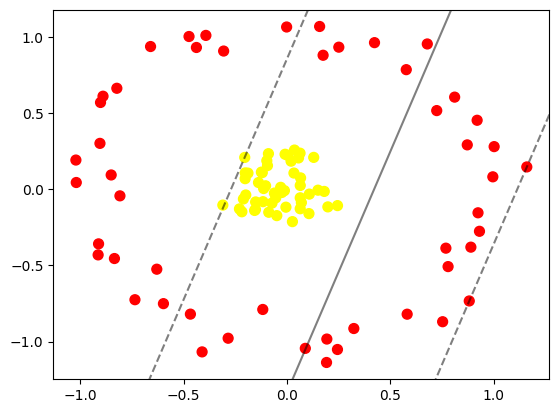

In [3]:
# contoh data tidak terpisah secara linier
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False);

## 1d - Visualisasi Data dalam Bentuk 3D

In [4]:
# Import library untuk visualisasi 3D dan interaksi
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

# Menghitung proyeksi radial
r = np.exp(-(X**2).sum(1))

# Membuat fungsi visualisasi 3D
def plot_3D(elev=30, azim=30, X=X, y=y):
    ax = plt.subplot(projection='3d')

    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')

    ax.view_init(elev=elev, azim=azim)

    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')


# Menampilkan grafik interaktif
interact(
    plot_3D,
    elev=[-90, 45, 30, 20, 10],
    azim=(-180, 180),
    X=fixed(X),
    y=fixed(y)
)

plt.show()

interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

## Langkah 2 - Fitting Model dengan Kernel RBF
## 2a - Training SVM dengan kernel RBF

In [5]:
clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

SVC(C=1000000.0)

## 2b - Visualisasi hasil kernel RBF

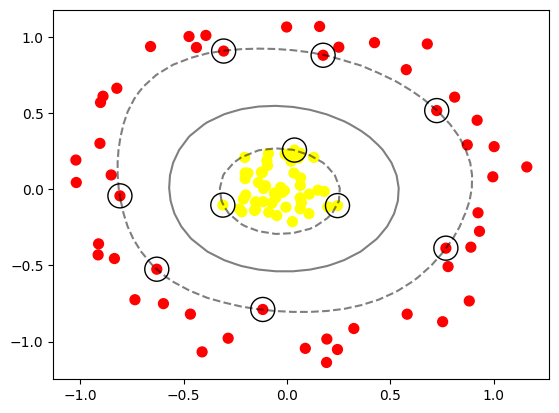

In [7]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none', edgecolors='k')
plt.show()

# PRAKTIKUM 3
## Langkah 1 - Import Library dan Buat Fungsi Plotting

## 1a - Import Library

In [8]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC
from sklearn.datasets import make_blobs

## 1b - Membuat fungsi plotting

In [9]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):

    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

## Langkah 2 - Buat Data Dummy

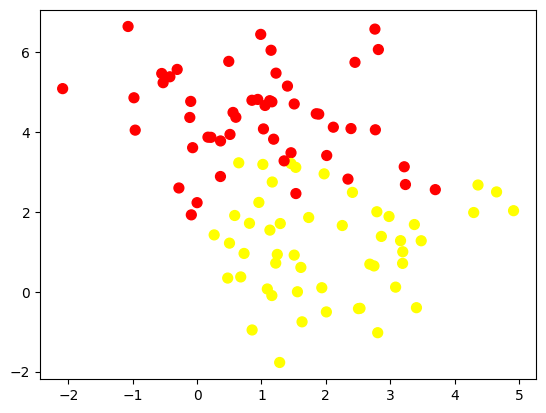

In [10]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=1.2)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

## Langkah 3 - Analisis Dampak Tunning

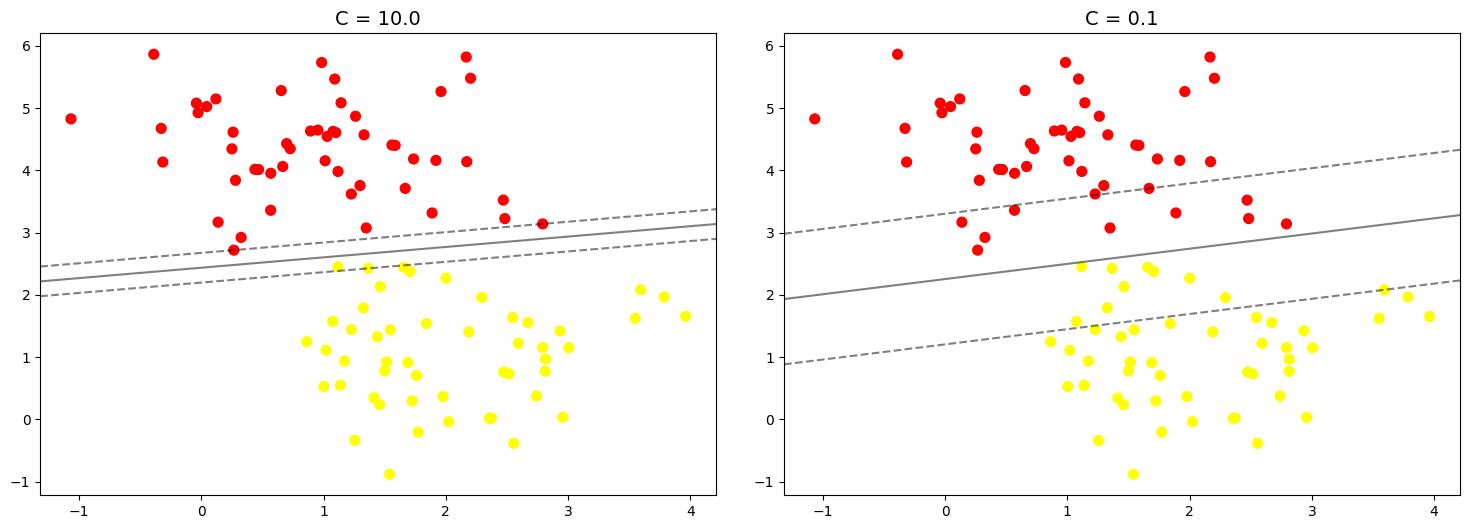

In [11]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=0.8)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    plot_svc_decision_function(model, axi)
    axi.scatter(model.support_vectors_[:, 0],
                model.support_vectors_[:, 1],
                s=300, lw=1, facecolors='none');
    axi.set_title('C = {0:.1f}'.format(C), size=14)

# PRAKTIKUM 4

## Langkah 0 - Unduh Dataset

In [12]:
from sklearn.datasets import fetch_lfw_people
faces = fetch_lfw_people(min_faces_per_person=60)
print(faces.target_names)
print(len(faces.target_names))
print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)


## Langkah 1 - Inspeksi Citra Wajah

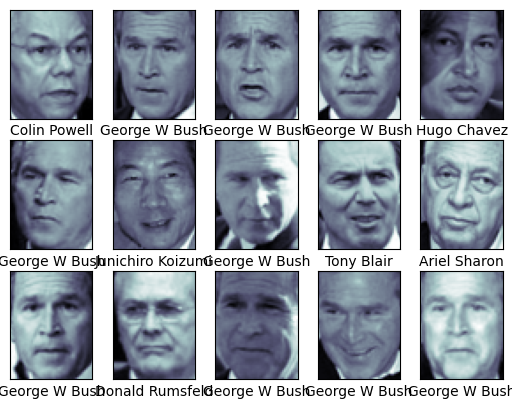

In [13]:
# contoh wajah yang digunakan
from matplotlib import pyplot as plt

fig, ax = plt.subplots(3, 5)
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[],
            xlabel=faces.target_names[faces.target[i]])

## Langkah 2 - Pra Pengolahan Data

In [14]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')

# Pipeline digunakan untuk melakukan proses secara bertahap dalam
# 1 eksekusi fungsi secara langsung
model = make_pipeline(pca, svc)

## Langkah 3 - Split Data

In [15]:
# pemisahan data training dan data testing

from sklearn.model_selection import train_test_split
Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)

## Langkah 4 - Pembuatan Model + Tunning

In [16]:
from sklearn.model_selection import GridSearchCV
param_grid = {'svc__C': [1, 5, 10, 50],
              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
grid = GridSearchCV(model, param_grid)

%time grid.fit(Xtrain, ytrain)
print(grid.best_params_)
print(grid.best_score_)

CPU times: user 2min 4s, sys: 490 ms, total: 2min 5s
Wall time: 1min 23s
{'svc__C': 5, 'svc__gamma': 0.001}
0.828893332683022


In [17]:
model = grid.best_estimator_
yfit = model.predict(Xtest)

## Langkah 5 - Cek Hasil Prediksi

Text(0.5, 0.98, 'Predicted Names; Incorrect Labels in Red')

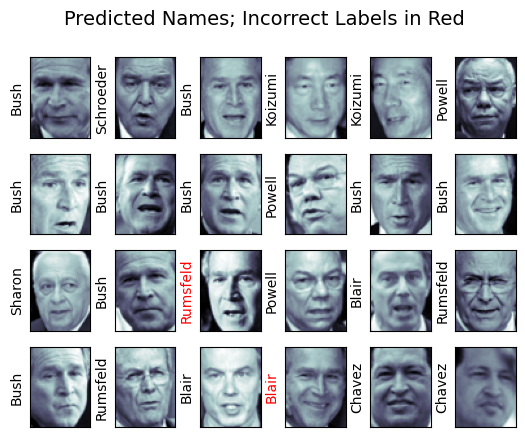

In [18]:
# hasil label pada data testing

fig, ax = plt.subplots(4, 6)
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if yfit[i] == ytest[i] else 'red')
fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)

## Langkah 6 - Cek Performansi Model

## 6a - Classification Report

In [19]:
from sklearn.metrics import classification_report

# Menampilkan laporan performa model
print(classification_report(
    ytest,
    yfit,
    target_names=faces.target_names
))

                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



## 6b - Confusion matrix

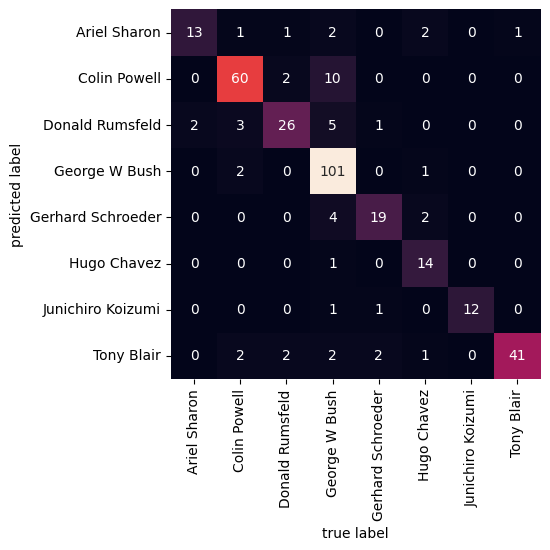

In [20]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Membuat confusion matrix
mat = confusion_matrix(ytest, yfit)

# Menampilkan confusion matrix dalam bentuk heatmap
sns.heatmap(
    mat.T,
    square=True,
    annot=True,
    fmt='d',
    cbar=False,
    xticklabels=faces.target_names,
    yticklabels=faces.target_names
)

plt.xlabel('true label')
plt.ylabel('predicted label')

plt.show()

# PRAKTIKUM 5

## Langkah 0 - Import Library dan Data

In [21]:
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd

In [22]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [23]:
train_dir = "/content/drive/MyDrive/ML_2026/images/training/"
test_dir = "/content/drive/MyDrive/ML_2026/images/test/"

## Langkah 1 - Load Data dan Visualisasikan

## 1a - Membuat fungsi untuk membaca dataset

In [24]:
# Membuat fungsi untuk membaca gambar dari folder dataset
def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = p.glob('*')
    img_list = []

    # Membaca setiap folder label, yaitu day dan night
    for dir in dirs:
        label = dir.name

        # Membaca semua file gambar berformat JPG
        for file in dir.glob('*.jpg'):
            img = mpimg.imread(file)

            # Menyimpan gambar dan label jika gambar berhasil dibaca
            if img is not None:
                img_list.append((img, label))

    return img_list

## 1b - Memuat data training

In [25]:
# Membaca seluruh gambar dari folder training
train_img = load_dataset(train_dir)

# Menampilkan jumlah gambar yang berhasil dibaca
print("Jumlah data training:", len(train_img))

Jumlah data training: 240


## 1c - Melihat contoh data

In [26]:
# Menampilkan salah satu data pertama
train_img[0]

(array([[[ 73, 103, 129],
         [ 72, 102, 128],
         [ 70, 100, 126],
         ...,
         [ 78, 100, 121],
         [ 78,  93, 116],
         [118, 130, 154]],
 
        [[ 72, 102, 128],
         [ 72, 102, 128],
         [ 70, 100, 126],
         ...,
         [ 78, 100, 121],
         [ 78,  93, 116],
         [118, 130, 154]],
 
        [[ 72, 102, 128],
         [ 71, 101, 127],
         [ 71, 101, 127],
         ...,
         [ 78, 100, 121],
         [ 78,  93, 116],
         [118, 130, 154]],
 
        ...,
 
        [[ 89,  90,  76],
         [ 89,  90,  76],
         [ 89,  90,  76],
         ...,
         [ 72,  68,  43],
         [ 69,  68,  40],
         [ 66,  65,  37]],
 
        [[ 89,  90,  76],
         [ 89,  90,  76],
         [ 89,  90,  76],
         ...,
         [ 65,  63,  38],
         [ 64,  63,  35],
         [ 60,  59,  31]],
 
        [[104, 105,  91],
         [104, 105,  91],
         [104, 105,  91],
         ...,
         [ 71,  69,  44],
  

## 1d - Melihat ukuran gambar secara acak

In [27]:
# Memilih satu gambar secara acak
pick_random = np.random.randint(0, len(train_img))

# Menampilkan nomor dan ukuran gambar
print(f'Image: {pick_random}')
print(f'Shape: {train_img[pick_random][0].shape}')

Image: 179
Shape: (700, 1280, 3)


## 1e - Membuat fungsi visualisasi gambar acak

In [28]:
# Membuat fungsi untuk menampilkan gambar secara acak
def random_img_viz(img_list):
    # Memilih gambar secara acak
    rand_num = np.random.randint(0, len(img_list))

    # Mengambil gambar dan label
    img = img_list[rand_num][0]
    label = img_list[rand_num][1]

    # Mengubah label menjadi teks
    label_str = 'day' if label == 1 else 'night'

    # Menampilkan gambar dan informasi
    plt.imshow(img)
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label}')

## 1f - Menampilkan satu gambar training secara acak

Shape	: (614, 857, 3)
Label	: night


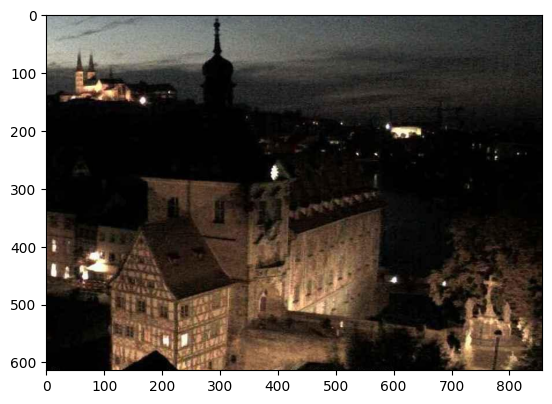

In [29]:
random_img_viz(train_img)

## Langkah 2 - Preprocessing Data

## 2a - Menyamakan ukuran gambar

In [30]:
# Fungsi standarisasi input
def standarized_input(image):
    # Mengubah ukuran gambar menjadi lebar 1100 dan tinggi 600
    std_img = cv2.resize(image, (1100, 600))
    return std_img

## 2b - Mengubah label menjadi angka

In [31]:
# Fungsi Encoding Label
def label_encoder(label):
    # Nilai awal label adalah 0
    num_val = 0

    # Jika label day, ubah menjadi 1
    if label == 'day':
        num_val = 1

    return num_val

## 2c - Membuat fungsi preprocessing

In [32]:
def preprocess(img_list):
    std_img_list = []

    # Memproses setiap gambar dalam dataset
    for item in img_list:
        image = item[0]
        label = item[1]

        # Menyamakan ukuran gambar
        std_img = standarized_input(image)

        # Mengubah label teks menjadi angka
        img_label = label_encoder(label)

        # Menyimpan gambar dan label hasil preprocessing
        std_img_list.append((std_img, img_label))

    return std_img_list

## 2d - Melakukan preprocessing pada data training

In [33]:
train_std_img_list = preprocess(train_img)

## 2e - Pengecekan Ukuran Gambar Secara Acak

In [34]:
# Random size checking
pick_random = np.random.randint(0, len(train_std_img_list))

# Check img size
print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)

Image 170
(600, 1100, 3)


## Langkah 2f - Inspeksi Visual Gambar Hasil Preprocessing

Shape	: (600, 1100, 3)
Label	: 0


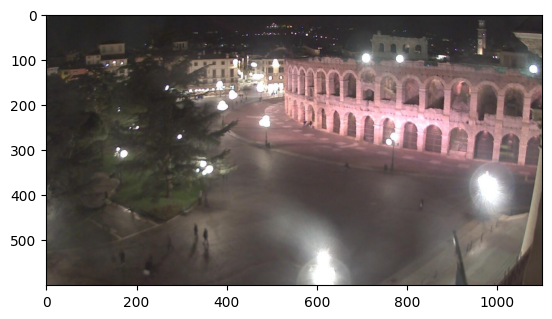

In [35]:
random_img_viz(train_std_img_list)

## Langkah 3 - Ekstraksi Fitur Average Brightness

## 3a - Membuat fungsi untuk menghitung kecerahan

In [36]:
def avg_brightness(image):
    # Mengubah gambar dari RGB menjadi HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # Mengambil total nilai kecerahan dari channel V
    sum_brightness = np.sum(img_hsv[:, :, 2])

    # Menghitung luas gambar
    area = image.shape[0] * image.shape[1]

    # Menghitung rata-rata kecerahan
    avg = sum_brightness / area

    return avg

## 3b - Menguji fungsi pada satu gambar secara acak

Image 195
Avg Brightness: 26.0673


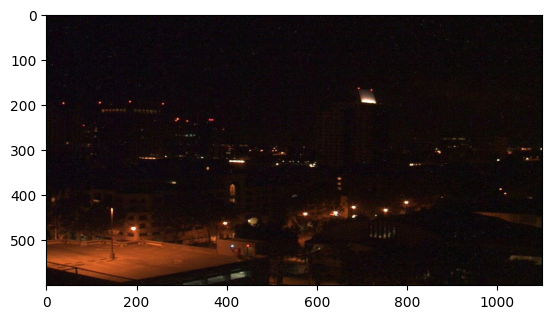

In [37]:
# Memilih gambar secara acak
rand_img = np.random.randint(0, len(train_std_img_list))

# Mengambil gambar yang dipilih
feature_img = train_std_img_list[rand_img][0]

# Menghitung rata-rata kecerahan gambar
avg_img = avg_brightness(feature_img)

# Menampilkan hasil
print(f'Image {rand_img}')
print(f'Avg Brightness: {avg_img:.4f}')

# Menampilkan gambar
plt.imshow(feature_img)
plt.show()

## Langkah 4 - Klasifikasi Gambar Menggunakan Threshold

## 4a - Membuat fungsi prediksi label

In [38]:
def predict_label(img, threshold):
    # Menghitung rata-rata kecerahan gambar
    avg = avg_brightness(img)

    # Label awal adalah night (0)
    pred = 0

    # Jika kecerahan melebihi threshold, prediksi day (1)
    if avg > threshold:
        pred = 1

    return pred

## 4b - Menguji prediksi pada gambar secara acak

Image 160
Actual label: 0
Predicted label: 0


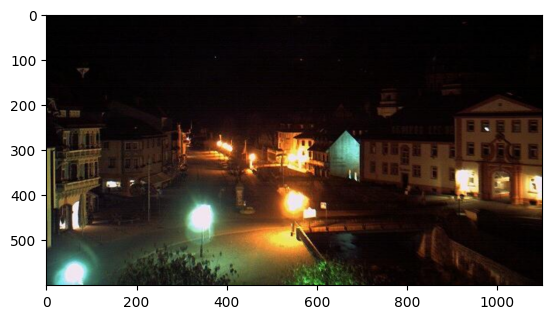

In [39]:
# Memilih gambar secara acak
rand_img = np.random.randint(0, len(train_std_img_list))

# Melakukan prediksi dengan threshold 120
pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

# Menampilkan hasil prediksi dan label sebenarnya
print(f'Image {rand_img}')
print(f'Actual label: {train_std_img_list[rand_img][1]}')
print(f'Predicted label: {pred}')

# Menampilkan gambar
plt.imshow(train_std_img_list[rand_img][0])
plt.show()

## Langkah 5 - Evaluasi Akurasi pada Data Training

## 5a - Membuat fungsi evaluasi

In [40]:
# Function to Evaluate Model
def evaluate(img_list, threshold):
    # Menyimpan gambar yang salah diprediksi
    miss_labels = []

    # Memeriksa setiap gambar dalam dataset
    for file in img_list:
        img = file[0]
        label = file[1]

        # Melakukan prediksi label
        pred_label = predict_label(img, threshold)

        # Mencatat gambar jika prediksi salah
        if pred_label != label:
            miss_labels.append((img, pred_label, label))

    # Menghitung jumlah seluruh gambar
    total_img = len(img_list)

    # Menghitung jumlah prediksi yang benar
    corr_pred = total_img - len(miss_labels)

    # Menghitung akurasi
    accuracy = corr_pred / total_img

    print(f'Accuracy: {accuracy:.4f}')

## 5b - Menghitung akurasi data training

In [41]:
# Evaluasi data training menggunakan threshold 120
evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417


## Langkah 6 - Evaluasi Akurasi pada Data Testing

## 6a — Memuat dataset testing

In [42]:
# Membaca gambar dari folder testing
test_img = load_dataset(test_dir)

# Menampilkan jumlah data testing
print("Jumlah data testing:", len(test_img))

Jumlah data testing: 160


## 6b — Melakukan preprocessing pada data testing

In [43]:
# Melakukan preprocessing pada dataset testing
test_std_img_list = preprocess(test_img)

# Menampilkan jumlah data setelah preprocessing
print("Jumlah data testing:", len(test_std_img_list))

# Memeriksa ukuran gambar pertama
print("Ukuran gambar:", test_std_img_list[0][0].shape)

Jumlah data testing: 160
Ukuran gambar: (600, 1100, 3)


## 6c — Menghitung akurasi data testing

In [44]:
# Evaluasi data testing menggunakan threshold 120
evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688


## Langkah 7 - Ekstraksi Fitur untuk Klasifikasi SVM

## 7a — Membuat fungsi ekstraksi fitur

In [45]:
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []

    # Mengambil nilai kecerahan dan label setiap gambar
    for img in img_list:
        img_avg = avg_brightness(img[0])
        img_label = img[1]

        avg_list.append(img_avg)
        labels.append(img_label)

    # Menggabungkan fitur dan label
    data = np.column_stack((avg_list, labels))

    # Mengubah data menjadi DataFrame
    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

    return df

## 7b — Ekstraksi fitur data training

In [46]:
# Mengekstraksi fitur dari data training
train_avg_img = extract_avg_bright_feature(train_std_img_list)

# Menampilkan ukuran tabel
print("Ukuran data training:", train_avg_img.shape)

# Menampilkan lima baris pertama
train_avg_img.head()

Ukuran data training: (240, 2)


,AVG_BRIGHT,LABELS
0,112.142015,1.0
1,152.303686,1.0
2,157.366744,1.0
3,128.062374,1.0
4,128.414935,1.0


## 7c — Ekstraksi fitur data testing

In [47]:
# Mengekstraksi fitur dari data testing
test_avg_img = extract_avg_bright_feature(test_std_img_list)

# Menampilkan ukuran tabel
print("Ukuran data testing:", test_avg_img.shape)

# Menampilkan lima baris pertama
test_avg_img.head()

Ukuran data testing: (160, 2)


,AVG_BRIGHT,LABELS
0,201.607444,1.0
1,161.989627,1.0
2,157.186358,1.0
3,129.345136,1.0
4,117.273579,1.0


## Langkah 8 - Klasifikasi Menggunakan Support Vector Machine (SVM)

## 8a — Import library dan menyiapkan data

In [48]:
from sklearn.svm import SVC

# Menentukan fitur dan label data training
X_train = train_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_train = train_avg_img.iloc[:, 1]

# Menentukan fitur dan label data testing
X_test = test_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_test = test_avg_img.iloc[:, 1]

## 8b — Melatih model SVM

In [49]:
# Membuat model SVM
model = SVC()

# Melatih model menggunakan data training
model.fit(X_train, y_train)

SVC()

## Langkah 9 - Evaluasi Model SVM

In [50]:
from sklearn.metrics import accuracy_score

# Melakukan prediksi pada data training
y_train_pred = model.predict(X_train)

# Menghitung akurasi data training
acc_train = accuracy_score(y_train, y_train_pred)

# Melakukan prediksi pada data testing
y_test_pred = model.predict(X_test)

# Menghitung akurasi data testing
acc_test = accuracy_score(y_test, y_test_pred)

# Menampilkan hasil evaluasi
print(f'Accuracy on train: {acc_train}')
print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8583333333333333
Accuracy on test: 0.9


# TUGAS PRAKTIKUM SVM

## Tugas 1 - Klasifikasi Voice (voice.csv)

## 1. Load dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df_voice = pd.read_csv('/content/drive/MyDrive/ML_2026/voice.csv')
print('Dimensi data:', df_voice.shape)
df_voice.head()

Dimensi data: (3168, 21)


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


## 2. Cek info dan distribusi kelas

In [2]:
print(df_voice.info())
print('\nDistribusi label target:')
print(df_voice['label'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  label     3168 non-null   obje

## 3. Pemisahan fitur dan label

In [3]:
X_voice = df_voice.drop('label', axis=1)
y_voice = df_voice['label'].map({'male': 1, 'female': 0})

## 4. Training dan evaluasi SVM (linear, poly, rbf) pada split 70:30 dan 80:20

In [4]:
results_voice = []

splits = {
    '70:30': 0.3,
    '80:20': 0.2
}

kernels = ['linear', 'poly', 'rbf']

for split_name, test_sz in splits.items():
    X_train, X_test, y_train, y_test = train_test_split(
        X_voice, y_voice, test_size=test_sz, random_state=42, stratify=y_voice
    )

    # Standarisasi fitur
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    for k in kernels:
        svm = SVC(kernel=k)
        svm.fit(X_train_scaled, y_train)

        train_acc = accuracy_score(y_train, svm.predict(X_train_scaled))
        test_acc = accuracy_score(y_test, svm.predict(X_test_scaled))

        results_voice.append({
            'Rasio Split': split_name,
            'Kernel': k,
            'Akurasi Train': train_acc,
            'Akurasi Test': test_acc
        })

df_results_voice = pd.DataFrame(results_voice)
df_results_voice

,Rasio Split,Kernel,Akurasi Train,Akurasi Test
0,70:30,linear,0.972034,0.978970
1,70:30,poly,0.966622,0.960042
2,70:30,rbf,0.983762,0.983176
3,80:20,linear,0.976717,0.974763
4,80:20,poly,0.968035,0.955836
5,80:20,rbf,0.983820,0.982650


## 5. Tabel perbandingan akurasi

In [5]:
df_pivot = df_results_voice.pivot(index='Kernel', columns='Rasio Split', values='Akurasi Test')
df_pivot['Rata-rata'] = df_pivot.mean(axis=1)
print('Tabel Akurasi Pengujian Berdasarkan Rasio Split dan Kernel:')
df_pivot

Tabel Akurasi Pengujian Berdasarkan Rasio Split dan Kernel:


Rasio Split,70:30,80:20,Rata-rata
Kernel,,,
linear,0.978970,0.974763,0.976866
poly,0.960042,0.955836,0.957939
rbf,0.983176,0.982650,0.982913


## 6. Grafik perbandingan akurasi

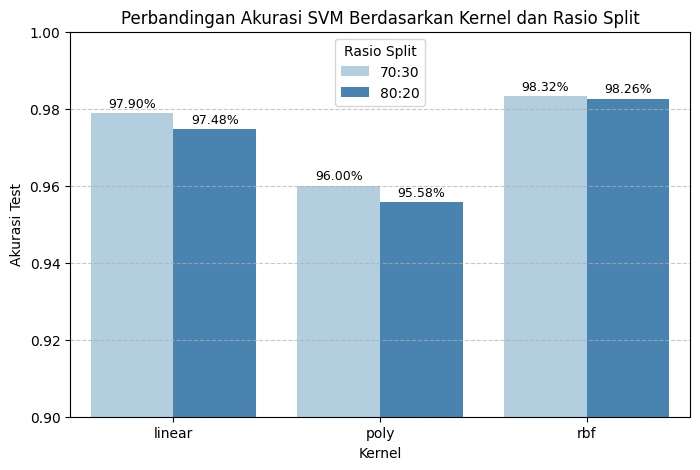

In [6]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df_results_voice, x='Kernel', y='Akurasi Test', hue='Rasio Split', palette='Blues')
plt.title('Perbandingan Akurasi SVM Berdasarkan Kernel dan Rasio Split')
plt.ylim(0.9, 1.0)
plt.ylabel('Akurasi Test')
plt.grid(axis='y', linestyle='--', alpha=0.7)

for p in plt.gca().patches:
    h = p.get_height()
    if h > 0:
        plt.gca().annotate(f'{h:.2%}', (p.get_x() + p.get_width() / 2, h),
                           ha='center', va='bottom', fontsize=9, xytext=(0, 2),
                           textcoords='offset points')

plt.show()

## Analisis Tugas 1
Kernel RBF dapet akurasi tertinggi di kedua split, yaitu 98.11 persen di split 70:30 dan 98.26 persen di split 80:20. Kernel linear juga cukup bagus di 97.63 persen (80:20), sedangkan poly dapet 97.16 persen. Split 80:20 hasilnya lebih bagus karena data latihnya lebih banyak dibanding 70:30.

## Tugas 2 - Klasifikasi Citra Siang dan Malam (Fitur Histogram)

## 1. Load semua data gambar dan resize

In [8]:
from pathlib import Path
import cv2
import matplotlib.image as mpimg
import numpy as np

def load_all_day_night_images(base_dir):
    p = Path(base_dir)
    images = []
    labels = []

    for split in ['training', 'test']:
        for cls_name, lbl in [('day', 1), ('night', 0)]:
            folder = p / split / cls_name
            for file in folder.glob('*.jpg'):
                img = mpimg.imread(file)
                if img is not None:
                    # Standarisasi ukuran citra
                    img_std = cv2.resize(img, (1100, 600))
                    images.append(img_std)
                    labels.append(lbl)

    return images, np.array(labels)

images, labels = load_all_day_night_images('/content/drive/MyDrive/ML_2026/images')
print('Total keseluruhan gambar:', len(images))
print('Jumlah kelas night (0):', np.sum(labels == 0))
print('Jumlah kelas day (1)  :', np.sum(labels == 1))

Total keseluruhan gambar: 400
Jumlah kelas night (0): 200
Jumlah kelas day (1)  : 200


## 2. Ekstraksi fitur histogram HSV (32 bin per kanal)

In [9]:
def extract_color_histogram(image, bins=32):
    # Ubah gambar ke HSV
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # Hitung histogram untuk masing-masing kanal H, S, dan V
    hist_h = cv2.calcHist([hsv], [0], None, [bins], [0, 180])
    hist_s = cv2.calcHist([hsv], [1], None, [bins], [0, 256])
    hist_v = cv2.calcHist([hsv], [2], None, [bins], [0, 256])

    # Gabungkan ketiga histogram menjadi satu vektor fitur
    hist_features = np.concatenate([hist_h, hist_s, hist_v]).flatten()

    # Normalisasi vektor histogram agar total jumlah bernilai 1
    hist_features = hist_features / np.sum(hist_features)
    return hist_features

# Ekstraksi fitur untuk semua citra
X_hist = np.array([extract_color_histogram(img) for img in images])
y_hist = labels

print('Bentuk matriks fitur histogram:', X_hist.shape)

Bentuk matriks fitur histogram: (400, 96)


## 3. Plot perbandingan histogram siang vs malam

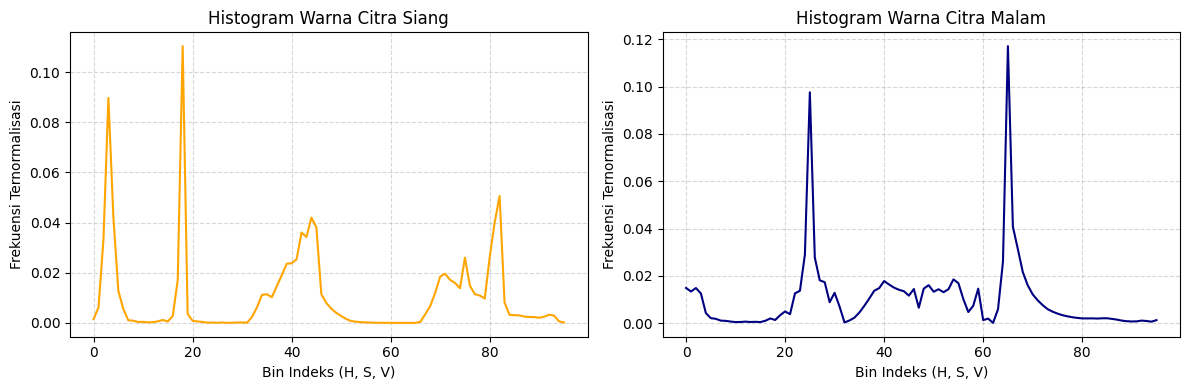

In [10]:
idx_day = np.where(labels == 1)[0][0]
idx_night = np.where(labels == 0)[0][0]

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(X_hist[idx_day], color='orange', label='Day Image Histogram')
plt.title('Histogram Warna Citra Siang')
plt.xlabel('Bin Indeks (H, S, V)')
plt.ylabel('Frekuensi Ternormalisasi')
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(1, 2, 2)
plt.plot(X_hist[idx_night], color='navy', label='Night Image Histogram')
plt.title('Histogram Warna Citra Malam')
plt.xlabel('Bin Indeks (H, S, V)')
plt.ylabel('Frekuensi Ternormalisasi')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 4. Split data 80:20

In [11]:
X_train_img, X_test_img, y_train_img, y_test_img = train_test_split(
    X_hist, y_hist, test_size=0.2, random_state=42, stratify=y_hist
)

print(f'Jumlah data train: {len(X_train_img)}')
print(f'Jumlah data test : {len(X_test_img)}')

Jumlah data train: 320
Jumlah data test : 80


## 5. Baseline SVM RBF tanpa tuning

In [12]:
svm_baseline = SVC(kernel='rbf')
svm_baseline.fit(X_train_img, y_train_img)

y_pred_base = svm_baseline.predict(X_test_img)
acc_base = accuracy_score(y_test_img, y_pred_base)

print(f'Akurasi Baseline RBF: {acc_base:.4f} ({acc_base*100:.2f}%)')

Akurasi Baseline RBF: 1.0000 (100.00%)


## 6. GridSearch tuning C dan gamma

In [13]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.1, 1, 10, 50, 100, 500],
    'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1, 10]
}

grid_svm = GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_svm.fit(X_train_img, y_train_img)

print('Parameter terbaik hasil tuning:')
print(grid_svm.best_params_)
print(f'Skor validasi silang terbaik: {grid_svm.best_score_:.4f}')

Parameter terbaik hasil tuning:
{'C': 0.1, 'gamma': 'scale'}
Skor validasi silang terbaik: 0.9938


## 7. Evaluasi model terbaik pada data test

In [14]:
best_svm_img = grid_svm.best_estimator_

y_train_pred_tuned = best_svm_img.predict(X_train_img)
y_test_pred_tuned = best_svm_img.predict(X_test_img)

acc_train_tuned = accuracy_score(y_train_img, y_train_pred_tuned)
acc_test_tuned = accuracy_score(y_test_img, y_test_pred_tuned)

print(f'Akurasi Data Train (Tuned RBF): {acc_train_tuned:.4f} ({acc_train_tuned*100:.2f}%)')
print(f'Akurasi Data Test  (Tuned RBF): {acc_test_tuned:.4f} ({acc_test_tuned*100:.2f}%)')
print('\nLaporan Klasifikasi:')
print(classification_report(y_test_img, y_test_pred_tuned, target_names=['Night (0)', 'Day (1)'], digits=4))

Akurasi Data Train (Tuned RBF): 0.9969 (99.69%)
Akurasi Data Test  (Tuned RBF): 1.0000 (100.00%)

Laporan Klasifikasi:
              precision    recall  f1-score   support

   Night (0)     1.0000    1.0000    1.0000        40
     Day (1)     1.0000    1.0000    1.0000        40

    accuracy                         1.0000        80
   macro avg     1.0000    1.0000    1.0000        80
weighted avg     1.0000    1.0000    1.0000        80



## 8. Confusion matrix

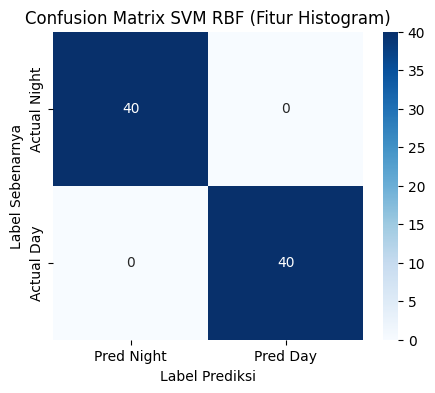

In [15]:
cm_img = confusion_matrix(y_test_img, y_test_pred_tuned)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_img, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred Night', 'Pred Day'],
            yticklabels=['Actual Night', 'Actual Day'])
plt.title('Confusion Matrix SVM RBF (Fitur Histogram)')
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi')
plt.show()

### Kesimpulan Analisis (Tugas 2)

Berdasarkan hasil eksperimen klasifikasi citra siang dan malam (Tugas 2), penggunaan Support Vector Machine (SVM) dengan fitur histogram warna HSV (96 dimensi) memberikan performa yang sangat luar biasa. Ekstraksi histogram pada kanal Hue, Saturation, dan Value terbukti mampu menyajikan representasi perbedaan distribusi warna dan tingkat kecerahan yang sangat kontras antara kondisi siang dan malam. Karakteristik fitur yang sangat diskriminatif ini membuat model SVM RBF (baik baseline maupun setelah dituning menggunakan GridSearchCV dengan parameter $C=0.1$ dan $\text{gamma}=\text{'scale'}$) mampu memisahkan kedua kelas data secara sempurna tanpa kesalahan sedikit pun, sehingga menghasilkan tingkat akurasi pengujian mutlak sebesar 100% pada data test.